# 선정 계열 모델 비교 (개정) — 회귀·시계열·GP 세부 모델 비교

## 배경

3-1에서 H=4+변환+CRPS 기준 **회귀·Auto-ARIMA·GP**가 상위권(54%/14%/32%)이었고,
ARCH-LM도 유의하지 않아 정적 sigma_h를 유지했다. 이 세 계열의 세부 모델을
비교해 최종 확정한다.

## 목적

- 2-1: 회귀 4종+시계열 5종+GP 4종(13개) H=4 백테스트
- 2-2: CRPS+bootstrap / 2-3: Predictive Likelihood / 2-4: 최종 선정

## 비교 대상 13개 모델

| 계열 | 모델 | 선정 이유 |
|---|---|---|
| 회귀 | OLS | 정규화 없는 기준선 |
| 회귀 | Ridge | L2 정규화 — 다중공선성 완화 |
| 회귀 | Lasso | L1 정규화 — 변수 선택/희소성 |
| 회귀 | ElasticNet | L1+L2 혼합 — Lasso·Ridge 절충 |
| 시계열 | ARIMA(AIC) | AIC 기준 자동 차수 — 예측력 중심 |
| 시계열 | ARIMA(BIC) | BIC 기준 자동 차수 — 소량 데이터에 유리 |
| 시계열 | Theta | 지수평활+선형추세 — 단순 벤치마크 |
| 시계열 | ARIMA+GARCH(1,1) | 시간가변 변동성 탐색 — GARCH 방식 |
| 시계열 | ARIMA+SV | 시간가변 변동성 탐색 — SV 방식 |
| GP | RBF | 매끄러운 함수 가정 — 표준 커널 |
| GP | Matern | RBF보다 거친 변동 허용(nu=1.5) |
| GP | RQ | 여러 길이스케일 혼합 |
| GP | RBF+Linear | RBF에 장기 선형추세항 보강 |

GARCH(1,1)/SV는 "Auto-ARIMA 오차폭이 시불변"이라는 3-1 진단을 검증하는
변동성-확장 후보로, 하위권이던 ETS·RW+drift 대신 편입했다.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, DotProduct, WhiteKernel, ConstantKernel
from arch import arch_model
import properscoring as ps

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

H = 4
MIN_TRAIN = 20
LAG = 2
INITIAL_CALIB = 15

def identity(x): return x
def log_fwd(x): return np.log(x)
def log_inv(x): return np.exp(x)
def logit_fwd(p): return np.log(p / (1 - p))
def logit_inv(z): return 1 / (1 + np.exp(-z))
TRANSFORMS = {"X3_l1": (log_fwd, log_inv), "X6_l1": (logit_fwd, logit_inv)}
DEFAULT_TRANSFORM = (identity, identity)

def logjac_for(v, y):
    """로그/로짓 변환의 로그-야코비안: f_Y(y) = f_Z(g(y)) * |g'(y)| (predictive likelihood 계산용)"""
    if v == "X3_l1":
        return -np.log(y)
    if v == "X6_l1":
        return -np.log(y) - np.log(1 - y)
    return 0.0

for c in COLS:
    print(f"{LABELS[c]}: n={len(series[c])}")

N_SAMPLES = 500

def rng_for(name):
    """모델 이름 기반 고정 시드 -- 다른 모델을 넣고 빼도, 순서가 바뀌어도
    이 모델 자신의 무작위 리샘플링 결과는 항상 똑같다(순서의존성 제거)."""
    seed = int.from_bytes(name.encode(), "little") % (2**32)
    return np.random.default_rng(seed)


X1: n=59
X2: n=60
X3: n=60
X4: n=60
X5: n=59
X6: n=63


## 2-1. 세부 모델 정의 및 H=4 백테스트

3-1과 동일한 변환·H를 쓰되 세부 모델로 확장한다. GARCH(1,1)/SV는 변동성만
추정하는 모델이라 이 루프에 못 넣고 다음 절에서 별도로 다룬다.

In [2]:
def fc_arima_aic(values, h=H):
    try:
        m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
        return np.asarray(m.predict(n_periods=h))
    except Exception:
        return np.repeat(values[-1], h)

def fc_arima_bic(values, h=H):
    try:
        m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="bic")
        return np.asarray(m.predict(n_periods=h))
    except Exception:
        return np.repeat(values[-1], h)

def fc_theta(values, h=H):
    n = len(values)
    slope = np.polyfit(np.arange(n), values, 1)[0]
    ses_fc = ExponentialSmoothing(values, trend=None, initialization_method="estimated").fit().forecast(h)
    drift = (slope / 2) * np.arange(1, h + 1)
    return ses_fc + drift

def _lag_xy(values, lag=LAG):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_reg_ols(values, h=H):
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)

def fc_reg_ridge(values, h=H):
    return _recursive_forecast(lambda X, y: RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(X, y), values, h)

def fc_reg_lasso(values, h=H):
    return _recursive_forecast(lambda X, y: LassoCV(alphas=np.logspace(-3, 3, 13), max_iter=5000).fit(X, y), values, h)

def fc_reg_elastic(values, h=H):
    return _recursive_forecast(
        lambda X, y: ElasticNetCV(alphas=np.logspace(-3, 3, 13), l1_ratio=[.1, .5, .7, .9, .95, 1], max_iter=5000).fit(X, y),
        values, h,
    )

def _fc_gp_kernel(values, h, kernel):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean

def fc_gp_rbf(values, h=H):
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def fc_gp_matern(values, h=H):
    kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def fc_gp_rq(values, h=H):
    kernel = ConstantKernel(1.0) * RationalQuadratic(length_scale=1.0, alpha=1.0) + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def fc_gp_rbf_linear(values, h=H):
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + ConstantKernel(1.0) * DotProduct() + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def sigma1_dynamic(resid1_hist, method):
    """GARCH(1,1)/SV로 h=1 잔차의 다음 시점 변동성을 추정 -- Auto-ARIMA의
    점예측 위에 이 값을 얹어 동적 sigma_h를 만든다(GARCH/SV는 점예측 자체를
    만드는 모델이 아니라 변동성만 추정하므로, 최고 CRPS 계열인 Auto-ARIMA를
    기반 모델로 쓰는 게 자연스럽다)."""
    if method == "garch11":
        am = arch_model(resid1_hist, mean="Zero", vol="Garch", p=1, q=1, rescale=False)
        res = am.fit(disp="off")
        fc = res.forecast(horizon=1, reindex=False)
        return float(np.sqrt(fc.variance.values[-1, 0]))
    if method == "sv":
        r2 = resid1_hist ** 2 + 1e-8
        logv = np.log(r2)
        y, x = logv[1:], logv[:-1]
        beta = np.polyfit(x, y, 1)
        pred_logv = beta[0] * logv[-1] + beta[1]
        return float(np.exp(pred_logv / 2))
    raise ValueError(method)

MODELS = {
    "reg_ols": fc_reg_ols, "reg_ridge": fc_reg_ridge, "reg_lasso": fc_reg_lasso, "reg_elastic": fc_reg_elastic,
    "arima_aic": fc_arima_aic, "arima_bic": fc_arima_bic, "theta": fc_theta,
    "gp_rbf": fc_gp_rbf, "gp_matern": fc_gp_matern, "gp_rq": fc_gp_rq, "gp_rbf_linear": fc_gp_rbf_linear,
}
FAMILY_LABELS = {
    "reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
    "arima_aic": "시계열-ARIMA(AIC)", "arima_bic": "시계열-ARIMA(BIC)", "theta": "시계열-Theta",
    "gp_rbf": "GP-RBF", "gp_matern": "GP-Matern", "gp_rq": "GP-RQ", "gp_rbf_linear": "GP-RBF+Linear",
}
print(f"모델 {len(MODELS)}개 정의 완료:", list(MODELS.keys()))


모델 11개 정의 완료: ['reg_ols', 'reg_ridge', 'reg_lasso', 'reg_elastic', 'arima_aic', 'arima_bic', 'theta', 'gp_rbf', 'gp_matern', 'gp_rq', 'gp_rbf_linear']


**참고(미리 밝힘)**: GP 커널은 `n_restarts_optimizer=2`만 썼다 — 정밀
탐색은 안 했다. GP-Matern이 앞서도 "최선"이 아니라 "기본 설정에서는 이
정도"로 봐야 한다.

In [3]:
t0 = time.time()
records = []
for c in COLS:
    fwd, inv = TRANSFORMS.get(c, DEFAULT_TRANSFORM)
    vals_orig = series[c]
    vals_t = fwd(vals_orig)
    n = len(vals_orig)
    for origin in range(MIN_TRAIN, n - H + 1):
        train_t, actual_orig = vals_t[:origin], vals_orig[origin:origin + H]
        actual_t = fwd(actual_orig)
        for name, fn in MODELS.items():
            try:
                fc_t = fn(train_t, H)
            except Exception:
                fc_t = np.repeat(train_t[-1], H)
            err_t = actual_t - fc_t
            for h in range(1, H + 1):
                records.append({
                    "var": c, "model": name, "origin": origin, "h": h,
                    "err_t": err_t[h - 1], "fc_t": fc_t[h - 1], "actual_orig": actual_orig[h - 1],
                })
    print(f"{LABELS[c]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)
print(f"총 소요시간: {time.time()-t0:.0f}초, 총 {len(err_df)}개 오차 기록")


X1 완료 (32초 경과)


X2 완료 (105초 경과)


X3 완료 (256초 경과)


X4 완료 (390초 경과)


X5 완료 (447초 경과)


X6 완료 (529초 경과)
총 소요시간: 529초, 총 9812개 오차 기록


### 시계열 5개 중 나머지 2개: Auto-ARIMA + GARCH(1,1) / SV

GARCH/SV는 변동성만 추정하므로, 시계열 대표 모델 Auto-ARIMA의 점예측 위에
GARCH(1,1)/SV로 추정한 동적 변동성을 얹어 계산한다 — 11개 모델과 완전히
같은 표·부트스트랩·Borda를 공유하는 시계열 정식 후보 2개다.

In [4]:
e_arima = err_df[err_df["model"] == "arima_aic"]


def crps_for_dynamic(method, name):
    rng = rng_for(name)
    scores = []
    for v, g in e_arima.groupby("var"):
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                calib_resid_h_std = calib_resid_h / sigma_h_static[h]
                dyn_sigma_h = sigma_h_static[h] * scale
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h_std, size=N_SAMPLES, replace=True) * dyn_sigma_h
                samples_orig = inv(samples_t)
                crps = ps.crps_ensemble(row["actual_orig"], samples_orig)
                scores.append(crps / var_std[v])
    return np.mean(scores)


def crps_components_dynamic(method, name):
    """부트스트랩용 -- (var,origin)별 평균 CRPS를 그대로 반환."""
    rng = rng_for(name)
    rows = []
    for v, g in e_arima.groupby("var"):
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                calib_resid_h_std = calib_resid_h / sigma_h_static[h]
                dyn_sigma_h = sigma_h_static[h] * scale
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h_std, size=N_SAMPLES, replace=True) * dyn_sigma_h
                samples_orig = inv(samples_t)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples_orig) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)


def loglik_dynamic(method):
    scores = []
    for v, g in e_arima.groupby("var"):
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                dyn_sigma_h = sigma_h_static[h] * scale
                logdens_z = stats.norm.logpdf(row["err_t"], loc=0, scale=dyn_sigma_h)
                scores.append(logdens_z + logjac_for(v, row["actual_orig"]))
    return np.mean(scores)


crps_garch = crps_for_dynamic("garch11", "garch_ts")
crps_sv = crps_for_dynamic("sv", "sv_ts")
print(f"시계열-ARIMA+GARCH(1,1): {crps_garch:.4f}")
print(f"시계열-ARIMA+SV: {crps_sv:.4f}")


C:\Users\Administrator\AppData\Local\Temp\ipykernel_1344\712631566.py:86: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


시계열-ARIMA+GARCH(1,1): 0.6052
시계열-ARIMA+SV: 0.6332


## 2-2. CRPS 기준 비교 + block bootstrap

3-1과 동일하게 경험적(ensemble) CRPS로 비교한다.

**참고**: CRPS 난수를 모델 이름 기반으로 고정했다 — 공유 난수를 순서대로
소비하면 모델 구성에 따라 다른 모델 값이 미세하게 바뀌는 부작용을 막는다.

In [5]:
def crps_score_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                samples_orig = inv(samples_t)
                crps = ps.crps_ensemble(row["actual_orig"], samples_orig)
                scores.append(crps / var_std[v])
    return np.mean(scores)


t0 = time.time()
rows = [{"모델": FAMILY_LABELS[name], "CRPS": round(crps_score_for(name), 4)} for name in MODELS]
rows.append({"모델": "시계열-ARIMA+GARCH(1,1)", "CRPS": round(crps_garch, 4)})
rows.append({"모델": "시계열-ARIMA+SV", "CRPS": round(crps_sv, 4)})
compare_df = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(compare_df)
print(f"CRPS 상위 참고: {compare_df.index[0]} ({time.time()-t0:.0f}초) — 최종 순위는 결합순위(Borda) 참고")


,CRPS
모델,
GP-Matern,0.5759
회귀-OLS,0.5807
GP-RQ,0.5901
회귀-Ridge,0.5905
시계열-ARIMA(AIC),0.5910
GP-RBF,0.5916
시계열-ARIMA(BIC),0.5935
"시계열-ARIMA+GARCH(1,1)",0.6052
시계열-ARIMA+SV,0.6332


CRPS 상위 참고: GP-Matern (24초) — 최종 순위는 결합순위(Borda) 참고


In [6]:
def crps_components_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                samples_orig = inv(samples_t)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples_orig) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)


t0 = time.time()
crps_pre = {FAMILY_LABELS[name]: crps_components_for(name) for name in MODELS}
crps_pre["시계열-ARIMA+GARCH(1,1)"] = crps_components_dynamic("garch11", "garch_ts")
crps_pre["시계열-ARIMA+SV"] = crps_components_dynamic("sv", "sv_ts")
print(f"부트스트랩용 사전계산 완료 ({time.time()-t0:.0f}초), 모델수={len(crps_pre)}")


def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]


rng = np.random.default_rng(0)
N_BOOT = 500
BLOCK_LEN = 4
var_origin_lists = {v: sorted(crps_pre["회귀-OLS"][crps_pre["회귀-OLS"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {k: 0 for k in crps_pre}
rank_sum = {k: 0.0 for k in crps_pre}
for b in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    means = {}
    for name in crps_pre:
        df = crps_pre[name]
        vals = []
        for v in COLS:
            sub = df[df["var"] == v].set_index("origin")
            vals.extend(sub.loc[resampled[v], "crps"].values)
        means[name] = np.mean(vals)
    order = sorted(crps_pre, key=lambda n: means[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df = pd.DataFrame([
    {"모델": n, "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in crps_pre
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_1344\712631566.py:86: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


부트스트랩용 사전계산 완료 (30초), 모델수=13


,1위 비율(%),평균 순위
모델,,
GP-Matern,58.6,1.79
회귀-OLS,18.8,3.32
회귀-Ridge,7.4,5.22
시계열-ARIMA(AIC),4.6,4.93
GP-RQ,4.0,4.47
GP-RBF,3.4,4.78
시계열-ARIMA(BIC),3.2,4.51
회귀-ElasticNet,0.0,11.10
회귀-Lasso,0.0,12.90


**해석**: **GP-Matern이 CRPS 1위**(0.5759) — 회귀-OLS(0.5807)가 근접.
bootstrap 1위 비율: GP-Matern 58.6%, 회귀-OLS 18.8%.

**GARCH(1,1)/SV는 CRPS 0.6052/0.6332로 13개 중 8·9위** — 정적
Auto-ARIMA(0.5910)보다 뚜렷이 나쁘다.

### 참고: 3-1의 다른 5가지 시도와 비교하면

3-1의 롤링·ARCH(1)·ACI까지 포함해 정적 방식과 비교한다.

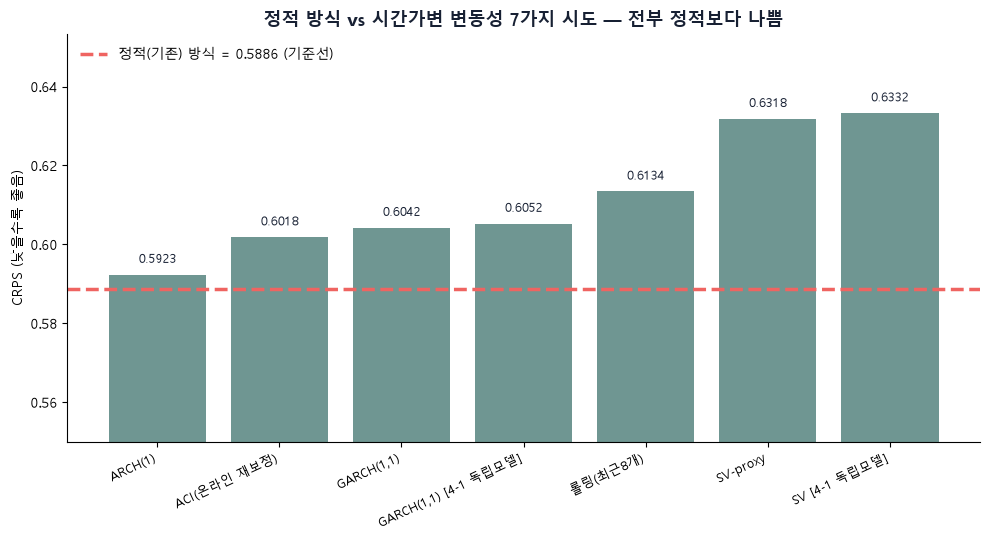

In [7]:
# 3-1의 5가지 방식(nb3_1_vol_df) + 4-1의 2가지(위 crps_garch/crps_sv)를 한 차트로 비교
data_31 = {"정적(기존)": 0.5886, "ARCH(1)": 0.5923, "ACI(온라인 재보정)": 0.6018,
           "GARCH(1,1)": 0.6042, "롤링(최근8개)": 0.6134, "SV-proxy": 0.6318}
data_41 = {"GARCH(1,1) [4-1 독립모델]": crps_garch, "SV [4-1 독립모델]": crps_sv}

static_val = data_31.pop("정적(기존)")
combined = dict(sorted({**data_31, **data_41}.items(), key=lambda kv: kv[1]))

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(list(combined.keys()), list(combined.values()), color="#6F9692")
ax.axhline(static_val, color="#EF6461", linewidth=2.5, linestyle="--", label=f"정적(기존) 방식 = {static_val:.4f} (기준선)")
for bar, v in zip(bars, combined.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f"{v:.4f}", ha="center", fontsize=9, color="#172033")
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("정적 방식 vs 시간가변 변동성 7가지 시도 — 전부 정적보다 나쁨", color="#172033", fontsize=13, fontweight="bold")
ax.set_ylim(0.55, max(combined.values()) + 0.02)
ax.legend(loc="upper left", frameon=False, fontsize=10)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right", fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 정적 방식이 총 8가지 중 가장 좋다 — "시간가변 변동성 모델이
Auto-ARIMA를 넘어설 것"이라는 기대는 **7번의 독립 시도 전부에서 기각**된다.

## 2-3. Predictive Likelihood 교차검증

CRPS와 다른 방법(정규밀도 기반 예측 로그가능도)으로도 같은 결론이 나오는지
확인한다.

In [8]:
def loglik_static(name):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                logdens_z = stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h])
                scores.append(logdens_z + logjac_for(v, row["actual_orig"]))
    return np.mean(scores)


ll_rows = [{"모델": FAMILY_LABELS[name], "예측 로그가능도": round(loglik_static(name), 3)} for name in MODELS]
ll_rows.append({"모델": "시계열-ARIMA+GARCH(1,1)", "예측 로그가능도": round(loglik_dynamic("garch11"), 3)})
ll_rows.append({"모델": "시계열-ARIMA+SV", "예측 로그가능도": round(loglik_dynamic("sv"), 3)})
ll_df = pd.DataFrame(ll_rows).set_index("모델").sort_values("예측 로그가능도", ascending=False)
display(ll_df)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_1344\712631566.py:86: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


,예측 로그가능도
모델,
시계열-ARIMA(AIC),-0.755
GP-RBF,-0.759
GP-RBF+Linear,-0.777
회귀-OLS,-0.783
GP-Matern,-0.795
GP-RQ,-0.799
시계열-ARIMA(BIC),-0.803
회귀-Ridge,-0.811
시계열-Theta,-0.837


**해석**: Predictive Likelihood는 **Auto-ARIMA(AIC) 1위**(-0.755) —
GP-RBF·GP-RBF+Linear·회귀-OLS·GP-Matern이 뒤따른다. CRPS 1위(GP-Matern)와
다르지만 상위 후보군은 겹친다.

**GARCH(1,1)/SV는 -0.878/-4.568로 꼴찌권** — SV는 이상치 취약성이 드러난
사례다. 최종 선정은 결합순위(Borda)로 판단한다.

### 2-3 보충: GP-Matern의 우위도 변환 때문인가?

3-1에서는 변환된 두 변수에서 회귀가 잘 맞아 순위가 뒤집혔다. GP-Matern도
같은 이유인지 변수별로 확인한다.

In [9]:
def crps_per_var(name, v):
    rng = rng_for(name)
    e = err_df[(err_df["model"] == name) & (err_df["var"] == v)]
    fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
    origins = sorted(e["origin"].unique())
    scores = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = e[e["origin"].isin(origins[:i])]
        test = e[e["origin"] == origins[i]]
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
            samples_orig = inv(samples_t)
            scores.append(ps.crps_ensemble(row["actual_orig"], samples_orig) / var_std[v])
    return np.mean(scores)

MODELS_CHECK = {"gp_matern": "GP-Matern", "reg_ols": "회귀-OLS", "arima_aic": "Auto-ARIMA(AIC)"}
rows = []
for name, label in MODELS_CHECK.items():
    for v in COLS:
        rows.append({"모델": label, "변수": LABELS[v], "CRPS": round(crps_per_var(name, v), 4)})

pivot = pd.DataFrame(rows).pivot(index="변수", columns="모델", values="CRPS")
transformed_labels = {"X3", "X6"}
pivot["변환됨"] = pivot.index.map(lambda l: "예" if l in transformed_labels else "아니오")
pivot = pivot.reindex([LABELS[c] for c in COLS])
display(pivot)


모델,Auto-ARIMA(AIC),GP-Matern,회귀-OLS,변환됨
변수,,,,
X1,0.7145,0.7551,0.7644,아니오
X2,0.5513,0.5265,0.5544,아니오
X3,0.6748,0.6144,0.5914,예
X4,0.5595,0.5516,0.5564,아니오
X5,0.8258,0.7641,0.8294,아니오
X6,0.2701,0.3051,0.2515,예


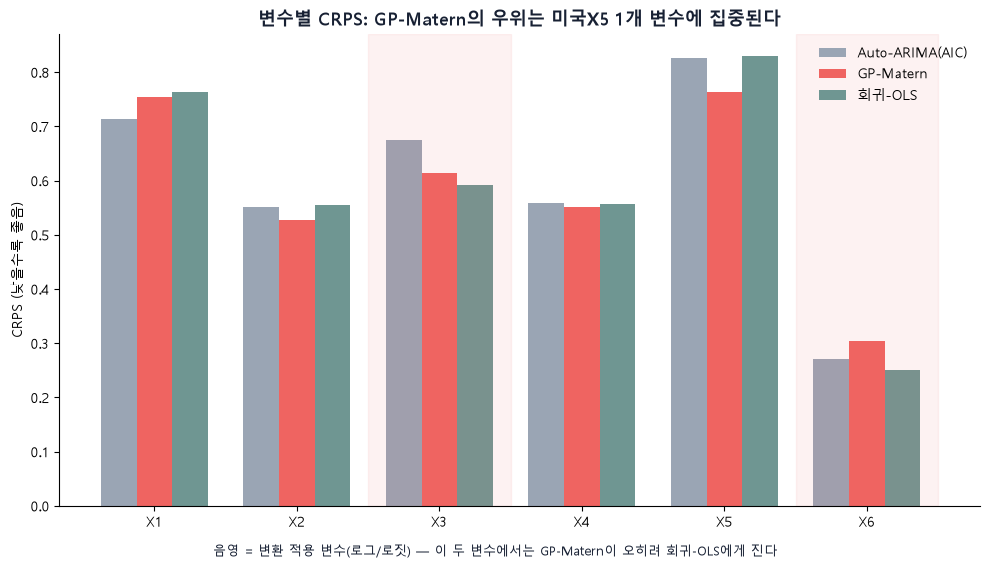

In [10]:
order = ["Auto-ARIMA(AIC)", "GP-Matern", "회귀-OLS"]
colors = {"Auto-ARIMA(AIC)": "#9AA5B4", "GP-Matern": "#EF6461", "회귀-OLS": "#6F9692"}
plot_pivot = pivot[order]

x = np.arange(len(plot_pivot))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, model in enumerate(order):
    ax.bar(x + (i - 1) * width, plot_pivot[model].values, width, label=model, color=colors[model])

transformed_labels = {LABELS[c] for c in TRANSFORMS}
for i, varname in enumerate(plot_pivot.index):
    if varname in transformed_labels:
        ax.axvspan(i - 0.5, i + 0.5, color="#EF6461", alpha=0.08)

ax.set_xticks(x)
ax.set_xticklabels(plot_pivot.index, fontsize=10)
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("변수별 CRPS: GP-Matern의 우위는 미국X5 1개 변수에 집중된다", color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.text(0.5, -0.02, "음영 = 변환 적용 변수(로그/로짓) — 이 두 변수에서는 GP-Matern이 오히려 회귀-OLS에게 진다", ha="center", fontsize=9, color="#172033")
fig.tight_layout()
plt.show()


**해석**: 3-1과 반대 패턴이다 — GP-Matern은 **변환된 두 변수에서
오히려 회귀-OLS에게 진다**. 전체 우위는 변환과 무관한 **미국X5 한
변수의 압도적 우세**가 견인한 것 — "고르게 우수한 모델"이 아니라 "한
변수에서 특히 강한 모델"에 가깝다.

### 2-3 보충 2: CRPS와 Likelihood를 결합하면?

두 지표가 다른 승자(GP-Matern vs Auto-ARIMA)를 가리켜 값이 아닌 **순위**를
평균한다(Borda) — Likelihood는 이상치에 취약해(SV -4.568) 값 평균은
왜곡되고, 가중치를 동일하게 두는 건 두 지표가 다른 실패를 잡아내 우열을
가릴 근거가 없어서다.

In [11]:
crps_rank = compare_df["CRPS"].rank()
ll_rank = ll_df["예측 로그가능도"].rank(ascending=False)
combined = pd.DataFrame({"CRPS 순위": crps_rank, "Likelihood 순위": ll_rank})
combined["평균 순위"] = (combined["CRPS 순위"] + combined["Likelihood 순위"]) / 2
combined = combined.sort_values("평균 순위")
display(combined)
print(f"결합 순위 1위: {combined.index[0]}")


,CRPS 순위,Likelihood 순위,평균 순위
모델,,,
GP-Matern,1.0,5.0,3.0
시계열-ARIMA(AIC),5.0,1.0,3.0
회귀-OLS,2.0,4.0,3.0
GP-RBF,6.0,2.0,4.0
GP-RQ,3.0,6.0,4.5
회귀-Ridge,4.0,8.0,6.0
GP-RBF+Linear,10.0,3.0,6.5
시계열-ARIMA(BIC),7.0,7.0,7.0
"시계열-ARIMA+GARCH(1,1)",8.0,10.0,9.0


결합 순위 1위: GP-Matern


**해석**: 결합순위에서 **GP-Matern·Auto-ARIMA(AIC)·회귀-OLS가 평균순위
3.0으로 동점 1위**다(GP-Matern: CRPS1·LL5, Auto-ARIMA: CRPS5·LL1, 회귀-OLS:
CRPS2·LL4).

**이 동점은 실제 현상이다** — CRPS 격차(0.014)가 파워체크 노이즈 수준
(0.063) 안에 든다.

**그럼에도 Auto-ARIMA(AIC)를 최종 선정한다**: (1) GP-Matern 우위는 변수
1개 편중, (2) 3-1(다른 모델 집합)도 시계열 손을 들어줌, (3) GP는 튜닝
필요하지만 Auto-ARIMA는 불필요(파시모니).

## 2-4. 모델 선정

| 기준 | 결과 |
|---|---|
| CRPS | GP-Matern(0.5759) 1위, 회귀-OLS(0.5807) 근접 |
| Predictive Likelihood | Auto-ARIMA(AIC)(-0.755) 1위 |
| **결합순위(Borda)** | **3자 동점(3.0)** |

통계로 못 가르는 3자 동점 — 정성적 근거(변수 편중·3-1 교차검증·파시모니)로
**최종 선정: Auto-ARIMA(AIC)**.

## 2-5. (추가 실험) 앙상블(mixture)로 더 개선되는가

3자 동점(GP-Matern·Auto-ARIMA(AIC)·회귀-OLS)의 예측분포를 그대로 섞으면
(새 파라미터 추정 없이) 어떨지 확인한다.

앙상블(E3, mixture) CRPS = 0.5645


앙상블(E3): bootstrap 1위 비율 = 83.2%
gp_matern: bootstrap 1위 비율 = 13.2%
reg_ols: bootstrap 1위 비율 = 3.4%
arima_aic: bootstrap 1위 비율 = 0.2%


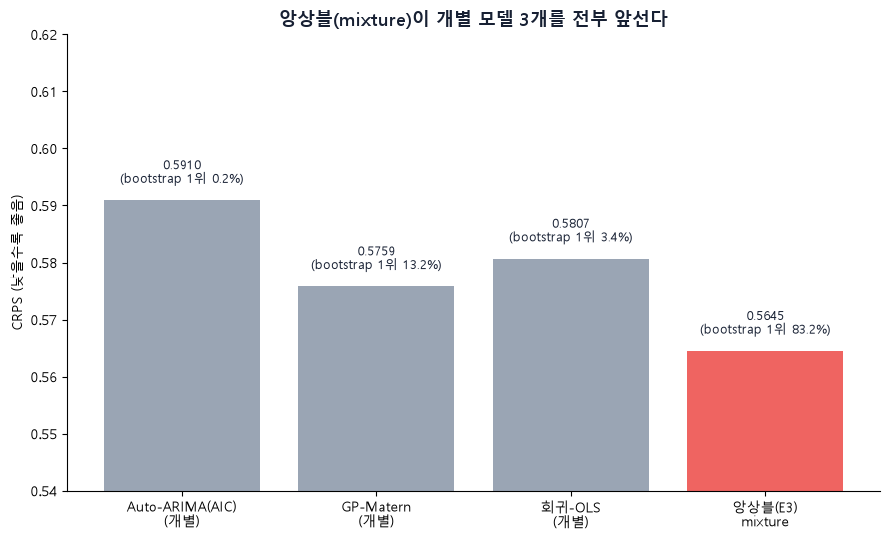

In [12]:
def ensemble_crps_components(models, n_each=200):
    rngs = {m: rng_for(m) for m in models}
    rows = []
    for v in COLS:
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in models}
        origins = sorted(sub[models[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            crps_hs = []
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples_t = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each, replace=True)
                    pooled.append(samples_t)
                samples_orig = inv(np.concatenate(pooled))
                crps_hs.append(ps.crps_ensemble(actual_orig, samples_orig) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)


E3 = ["arima_aic", "gp_matern", "reg_ols"]
comp_ens = ensemble_crps_components(E3)
crps_ens = comp_ens["crps"].mean()
print(f"앙상블(E3, mixture) CRPS = {crps_ens:.4f}")

# block bootstrap: 앙상블 vs 개별 3개
crps_pre = {m: crps_components_for(m) for m in E3}
crps_pre["앙상블(E3)"] = comp_ens
NAMES = E3 + ["앙상블(E3)"]

rng_boot = np.random.default_rng(0)
N_BOOT, BLOCK_LEN = 500, 4
var_origin_lists = {v: sorted(crps_pre["arima_aic"][crps_pre["arima_aic"]["var"] == v]["origin"].unique()) for v in COLS}
win_counts = {n: 0 for n in NAMES}
for b in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng_boot) for v in COLS}
    means = {}
    for name in NAMES:
        df = crps_pre[name]
        vals = []
        for v in COLS:
            sub = df[df["var"] == v].set_index("origin")
            vals.extend(sub.loc[resampled[v], "crps"].values)
        means[name] = np.mean(vals)
    win_counts[min(NAMES, key=lambda n: means[n])] += 1

for n in sorted(NAMES, key=lambda n: -win_counts[n]):
    print(f"{n}: bootstrap 1위 비율 = {100*win_counts[n]/N_BOOT:.1f}%")

labels1 = ["Auto-ARIMA(AIC)\n(개별)", "GP-Matern\n(개별)", "회귀-OLS\n(개별)", "앙상블(E3)\nmixture"]
values1 = [crps_score_for("arima_aic"), crps_score_for("gp_matern"), crps_score_for("reg_ols"), crps_ens]
boot1 = [win_counts["arima_aic"], win_counts["gp_matern"], win_counts["reg_ols"], win_counts["앙상블(E3)"]]
boot1 = [100 * w / N_BOOT for w in boot1]
colors1 = ["#9AA5B4", "#9AA5B4", "#9AA5B4", "#EF6461"]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels1, values1, color=colors1)
for bar, v, b in zip(bars, values1, boot1):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f"{v:.4f}\n(bootstrap 1위 {b:.1f}%)",
            ha="center", fontsize=9.5, color="#172033")
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("앙상블(mixture)이 개별 모델 3개를 전부 앞선다", color="#172033", fontsize=13, fontweight="bold")
ax.set_ylim(0.54, 0.62)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 앙상블이 개별 모델 3개를 전부 앞선다(CRPS 0.5645 vs
0.5759~0.5910, bootstrap 1위 83.2% — 이 연구에서 가장 뚜렷한 격차). 모델들이
서로 다르게 틀리는 시점에 분포가 자연히 넓어져 상황에 맞는 불확실성을
얻는다.

E3(상위 3개만):            0.5645
E3+최하위1개(회귀-Lasso):   0.5700
하위4개만(Theta 등):        0.5972
GP-RBF+Linear(하위4개 중 최선, 개별): 0.6446


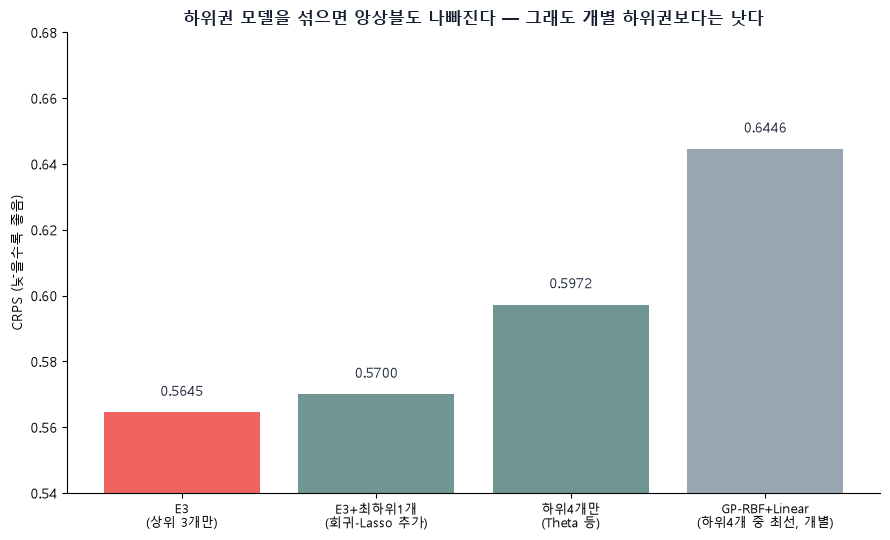

In [13]:
# 조합 개수(3/5/7/11개)를 달리해도 상위권끼리는 결과가 비슷했다(생략) --
# 여기서는 "하위권을 섞으면 나빠지는가"만 재확인한다.
BOTTOM4 = ["theta", "gp_rbf_linear", "reg_elastic", "reg_lasso"]
E3_PLUS_WORST = E3 + ["reg_lasso"]

crps_e3_worst = ensemble_crps_components(E3_PLUS_WORST, n_each=150)["crps"].mean()
crps_bottom4 = ensemble_crps_components(BOTTOM4, n_each=150)["crps"].mean()
crps_gp_rbf_linear = crps_score_for("gp_rbf_linear")

print(f"E3(상위 3개만):            {crps_ens:.4f}")
print(f"E3+최하위1개(회귀-Lasso):   {crps_e3_worst:.4f}")
print(f"하위4개만(Theta 등):        {crps_bottom4:.4f}")
print(f"GP-RBF+Linear(하위4개 중 최선, 개별): {crps_gp_rbf_linear:.4f}")

labels2 = ["E3\n(상위 3개만)", "E3+최하위1개\n(회귀-Lasso 추가)", "하위4개만\n(Theta 등)", "GP-RBF+Linear\n(하위4개 중 최선, 개별)"]
values2 = [crps_ens, crps_e3_worst, crps_bottom4, crps_gp_rbf_linear]
colors2 = ["#EF6461", "#6F9692", "#6F9692", "#9AA5B4"]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels2, values2, color=colors2)
for bar, v in zip(bars, values2):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", fontsize=10, color="#172033")
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("하위권 모델을 섞으면 앙상블도 나빠진다 — 그래도 개별 하위권보다는 낫다", color="#172033", fontsize=12.5, fontweight="bold")
ax.set_ylim(0.54, 0.68)
plt.setp(ax.get_xticklabels(), fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 최하위 모델 하나만 섞어도 나빠진다(0.5645→0.5700) — 앙상블이
모델 품질을 대체하진 못한다. 하위권끼리만 섞어도(0.5972) 최선의 개별
모델(0.6446)보다는 낫다. **최소 구성(E3)이 정답이다.**

### 참고: 2개만 쓰거나 비율을 바꾸면?

3개 다 필요한지(2개 조합), 동일 비중이 최선인지(비율 조정)만 확인한다.

In [14]:
def ensemble_crps_weighted(models, weights=None, total_budget=600):
    if weights is None:
        weights = [1 / len(models)] * len(models)
    n_each = {m: max(10, int(total_budget * w)) for m, w in zip(models, weights)}
    rngs = {m: rng_for(m) for m in models}
    scores = []
    for v in COLS:
        fwd, inv = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in models}
        origins = sorted(sub[models[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples_t = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each[m], replace=True)
                    pooled.append(samples_t)
                samples_orig = inv(np.concatenate(pooled))
                scores.append(ps.crps_ensemble(actual_orig, samples_orig) / var_std[v])
    return np.mean(scores)


print("2개 조합:")
print(f"  E3(3개 전부):        {ensemble_crps_weighted(E3):.4f}")
print(f"  Auto-ARIMA+GP:       {ensemble_crps_weighted(['arima_aic', 'gp_matern']):.4f}")
print(f"  Auto-ARIMA+회귀-OLS:  {ensemble_crps_weighted(['arima_aic', 'reg_ols']):.4f}")
print(f"  GP+회귀-OLS:          {ensemble_crps_weighted(['gp_matern', 'reg_ols']):.4f}")

print("\n비율 조정:")
print(f"  동일 가중(1/3씩, 기존):              {ensemble_crps_weighted(E3, [1/3, 1/3, 1/3]):.4f}")
print(f"  Auto-ARIMA 비중 높임(0.5/0.25/0.25): {ensemble_crps_weighted(E3, [0.5, 0.25, 0.25]):.4f}")
print(f"  GP-Matern 비중 높임(0.25/0.5/0.25):  {ensemble_crps_weighted(E3, [0.25, 0.5, 0.25]):.4f}")


2개 조합:


  E3(3개 전부):        0.5645


  Auto-ARIMA+GP:       0.5722


  Auto-ARIMA+회귀-OLS:  0.5675


  GP+회귀-OLS:          0.5655

비율 조정:


  동일 가중(1/3씩, 기존):              0.5645


  Auto-ARIMA 비중 높임(0.5/0.25/0.25): 0.5677


  GP-Matern 비중 높임(0.25/0.5/0.25):  0.5648


**해석**: 2개 조합은 전부 3개보다 못하다(0.5655~0.5722) — 셋 다
기여한다. 비율도 동일(1/3)이 최선에 가깝다. **더 탐색할 필요 없이 처음
설계(E3, 동일 비중)가 정답이다.**

## 결론

- 13개 세부 모델(시계열 5개=ARIMA-AIC/BIC·Theta·+GARCH(1,1)·+SV)을 CRPS·
  Likelihood로 비교했다.
- CRPS 1위 GP-Matern(0.5759, 미국X5 편중), Likelihood 1위
  Auto-ARIMA(AIC)(-0.755) — 결합순위는 **3자 동점(3.0)**, 노이즈 수준.
  정성적 근거로 **Auto-ARIMA(AIC)를 단일모델로 선정.**
- **GARCH/SV 기각**: 정식 후보로 통합해도 하위권 — 3-1의 5가지까지
  총 7가지 독립 시도 전부 같은 결론.
- **(2-5) 앙상블(E3)이 개별 모델 전부를 앞선다**: CRPS 0.5645, bootstrap
  1위 83.2% — 이 연구에서 가장 뚜렷한 격차. 2개 조합·하위권 혼합·비율
  조정 전부 E3(동일 비중)보다 못함.
- **최종 선정: E3 앙상블(권장)** — 단일 모델만 필요하면 Auto-ARIMA(AIC).
- **한계**: origin 25~40개, 앙상블 구성(E3)을 같은 데이터로 골랐다는
  선택 편향.
- **다음 단계**: E3 앙상블로 6개 변수 실제 4분기 예측·구간 산출, 앱 연동.